# Hito 2 — Sistema RAG

Sistema de verificación de hechos sobre mitología griega, romana y nórdica.

En el Hito 1 se construyó el corpus (5.035 documentos partidos en 19.792 fragmentos), un conjunto de 84 queries de evaluación y el baseline de recuperación dispersa: **BM25**, con Recall@10 = 0,845 y MRR = 0,645. En este hito se construye el sistema RAG completo:

1. **Recuperación densa**: los mismos fragmentos, representados con *sentence embeddings* y guardados en una base de datos vectorial, evaluados con las mismas queries y comparados con BM25.
2. **Generación**: un LLM de pesos abiertos que, con los fragmentos recuperados, da un veredicto sobre la afirmación, cita sus fuentes, no responde si no hay pruebas y contesta en el idioma de la pregunta.
3. **Evaluación de la generación**: calidad de los veredictos, cobertura y tiempo de respuesta.

La base vectorial se crea con `src/indexa_vectores.py`; aquí solo se carga.

In [1]:
import json
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Mismo estilo de gráficas que en el Hito 1, con un color fijo por método
plt.rcParams.update({
    'figure.dpi': 110, 'font.size': 9.5, 'axes.titlesize': 11, 'axes.titleweight': 'bold',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#8a8984',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'legend.frameon': False,
})
COLOR = {'BM25': '#2a78d6', 'e5': '#1baf7a', 'bge': '#eda100'}
GRIS = '#8a8984'

RAIZ = Path('..')
DATOS = RAIZ / 'data'
sys.path.append(str(RAIZ / 'src'))

def leer_jsonl(ruta):
    with open(ruta, encoding='utf-8') as f:
        return [json.loads(linea) for linea in f]

chunks = pd.DataFrame(leer_jsonl(DATOS / 'processed' / 'chunks.jsonl'))
chunks = chunks[['chunk_id', 'doc_id', 'fuente', 'titulo', 'seccion', 'n_palabras', 'texto']]
tokens = leer_jsonl(DATOS / 'processed' / 'chunks_tokens.jsonl')
assert [t['chunk_id'] for t in tokens] == chunks['chunk_id'].tolist()
corpus = [t['tokens'] for t in tokens]

queries = leer_jsonl(DATOS / 'queries.jsonl')
relevant = [set(q['relevant_ids']) for q in queries]
assert all(r <= set(chunks['doc_id']) for r in relevant), 'Hay queries cuyo documento no está en el corpus'

titulo_de_doc = chunks.drop_duplicates('doc_id').set_index('doc_id')['titulo']
doc_de_fila = chunks['doc_id'].values
fila_de_chunk = {cid: i for i, cid in enumerate(chunks['chunk_id'])}

print(f"{chunks['doc_id'].nunique()} documentos, {len(chunks)} fragmentos, {len(queries)} queries")

5035 documentos, 19792 fragmentos, 84 queries


Las funciones de evaluación son las del Hito 1, para que los números sean comparables:

- **De fragmentos a documentos**: para pedir $k$ documentos se recuperan $20k$ fragmentos (como mínimo 200) y cada documento puntúa con su mejor fragmento.
- **Métricas**: Recall@5, @10, @50 y @100 y MRR@10.
- **Intervalos de confianza del 95 %** por *bootstrap* (2.000 remuestreos de las queries) y **diferencias emparejadas** entre sistemas: una diferencia es clara si su intervalo no incluye el 0.

In [2]:
K, K_MAX = 10, 100
CORTES = (5, 10, 50, 100)
B_BOOTSTRAP = 2000

def n_fragmentos(k):
    return max(200, 20 * k)

def a_documentos(filas, k):
    # Los fragmentos vienen ordenados de mejor a peor: cada documento se queda con su primera aparición
    docs, vistos = [], set()
    for fila in filas:
        d = doc_de_fila[fila]
        if d not in vistos:
            vistos.add(d)
            docs.append(d)
            if len(docs) == k:
                break
    return docs

def posicion(ranking, rel):
    return next((i for i, d in enumerate(ranking, 1) if d in rel), None)

def aciertos(rankings, relevant, cortes=CORTES, k_mrr=K):
    # Una fila por query: Recall@K de cada corte y el recíproco de la posición (para el MRR)
    filas = []
    for r, rel in zip(rankings, relevant):
        fila = {f'Recall@{c}': len(set(r[:c]) & rel) / len(rel) for c in cortes}
        p = posicion(r[:k_mrr], rel)
        fila['MRR'] = 1 / p if p else 0.0
        filas.append(fila)
    return pd.DataFrame(filas)

def intervalo(valores, B=B_BOOTSTRAP, semilla=0):
    # Media e intervalo bootstrap del 95 %. Con la misma semilla se remuestrean las mismas queries:
    # aplicado a la diferencia query a query entre dos sistemas, es el bootstrap emparejado.
    v = np.asarray(valores, dtype=float)
    indices = np.random.default_rng(semilla).integers(0, len(v), size=(B, len(v)))
    inf, sup = np.percentile(v[indices].mean(axis=1), [2.5, 97.5])
    return v.mean(), inf, sup

def texto_ic(media, inf, sup):
    return f"{media:.3f} [{inf:.3f}, {sup:.3f}]"

def grafica_diferencias(ax, etiquetas, ics, color, desplazamiento=0, nombre=None):
    # Punto en la diferencia media y línea en su intervalo; relleno si el intervalo no incluye el 0
    y = np.arange(len(etiquetas))[::-1] + desplazamiento
    for yi, (media, inf, sup) in zip(y, ics):
        clara = inf > 0 or sup < 0
        ax.plot([inf, sup], [yi, yi], color=color, lw=2, solid_capstyle='round')
        ax.plot(media, yi, 'o', ms=8, color=color if clara else 'white', mec=color, mew=2,
                label=nombre if yi == y[0] else None)
    ax.axvline(0, color=GRIS, lw=1, ls='--')
    ax.set_yticks(np.arange(len(etiquetas))[::-1], etiquetas)
    ax.grid(axis='y', visible=False)

## 1. Recuperación densa

### 1.1. El baseline: BM25 del Hito 1

Se reconstruye BM25 con la configuración final del Hito 1 (`bm25s`, variante Lucene, $k_1 = 1.5$, $b = 0.75$, lemas de spaCy con el título delante, sin N-gramas, sin filtros y sin normalización). Las queries pasan por el mismo preprocesado que los fragmentos. Si todo está igual, deben salir las cifras del Hito 1: Recall@10 = 0,845 y MRR = 0,645.

In [3]:
import bm25s
from preprocesado import preparar

bm25 = bm25s.BM25(k1=1.5, b=0.75)
bm25.index(corpus, show_progress=False)
vocabulario = {w for doc in corpus for w in doc}
q_tokens = [[w for w in t if w in vocabulario] for t in preparar([q['query'] for q in queries])]

def retrieve_bm25(tokens_query, k=K):
    if not tokens_query:
        return []
    filas, _ = bm25.retrieve([tokens_query], k=n_fragmentos(k), show_progress=False)
    return a_documentos(filas[0], k)

rankings, tiempos = {}, {}
inicio = time.perf_counter()
rankings['BM25'] = [retrieve_bm25(t, k=K_MAX) for t in q_tokens]
tiempos['BM25'] = (time.perf_counter() - inicio) / len(queries)

a_bm25 = aciertos(rankings['BM25'], relevant)
print(a_bm25.mean().round(3).to_string())

/home/santihm/Fact-checking_system/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Recall@5      0.810
Recall@10     0.845
Recall@50     0.952
Recall@100    0.976
MRR           0.645


Salen exactamente las cifras del Hito 1 (Recall@10 = 0,845 y MRR = 0,645): el corpus, las queries y el preprocesado son los mismos, así que la comparación con la recuperación densa es justa.

### 1.2. Embeddings y base de datos vectorial

En la recuperación densa, cada fragmento se representa con un vector (*embedding*) que resume su significado, calculado con un modelo de lenguaje entrenado para que textos parecidos tengan vectores cercanos. La query se representa igual, y se recuperan los fragmentos cuyo vector está más cerca, con la **similitud coseno**. A diferencia de BM25, no hace falta que la query y el fragmento compartan palabras: *"the islands of the blessed"* puede quedar cerca de *"the Fortunate Isles"*.

**Modelos.** Se comparan dos:

| Modelo | Idiomas | Dimensión | Longitud máxima | Por qué |
|---|---|---|---|---|
| `intfloat/multilingual-e5-base` (**e5**) | ~100, entre ellos inglés y español | 768 | 512 *tokens* | Las afirmaciones pueden llegar en español y el corpus está en inglés: con un modelo multilingüe no hace falta traducir |
| `BAAI/bge-small-en-v1.5` (**bge**) | solo inglés | 384 | 512 *tokens* | Para medir si ser multilingüe cuesta algo con queries en inglés |

Los dos se usan como recomiendan sus autores: e5 con los prefijos `query:` y `passage:`, y bge con una instrucción delante de la query. Como en BM25, a cada fragmento se le pone delante el título de su documento. Con 512 *tokens* caben casi todos los fragmentos enteros: se cortan el 5,7 % con e5 y el 2,9 % con bge (el tokenizador multilingüe parte más las palabras, sobre todo los nombres griegos y nórdicos).

**Base de datos vectorial: Chroma.** Guarda en disco cada vector con su texto y con los datos para citar (documento, título, fuente, sección, URL). Busca los vecinos más cercanos con un índice HNSW, que es aproximado pero muy rápido; en la sección 1.4 se comprueba que la aproximación no cambia los resultados.

In [4]:
import chromadb
from sentence_transformers import SentenceTransformer
from indexa_vectores import MODELOS, RUTA_CHROMA, nombre_coleccion

cliente = chromadb.PersistentClient(path=str(RUTA_CHROMA))
modelos, colecciones = {}, {}
for clave in ['e5', 'bge']:
    modelos[clave] = SentenceTransformer(MODELOS[clave]['nombre'])
    colecciones[clave] = cliente.get_collection(nombre_coleccion(clave))
    print(f"{clave}: {MODELOS[clave]['nombre']}, {colecciones[clave].count()} vectores, "
          f"dispositivo {modelos[clave].device}")

def vector_query(texto, clave):
    return modelos[clave].encode([MODELOS[clave]['prefijo_query'] + texto], normalize_embeddings=True)

def retrieve_denso(texto, clave, k=K):
    res = colecciones[clave].query(query_embeddings=vector_query(texto, clave).tolist(),
                                   n_results=n_fragmentos(k), include=['distances'])
    return a_documentos([fila_de_chunk[cid] for cid in res['ids'][0]], k)

# Ejemplo con la primera query
q = queries[0]
print(f"\n{q['qid']} - {q['query']}\n     Relevante: {titulo_de_doc[q['relevant_ids'][0]]}")
for clave in ['e5', 'bge']:
    print(f"     {clave:4s}", [titulo_de_doc[d] for d in retrieve_denso(q['query'], clave, k=3)])

Loading weights: 100%|██████████| 199/199 [00:01<00:00, 115.68it/s]


e5: intfloat/multilingual-e5-base, 19792 vectores, dispositivo cuda:0


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 210.85it/s]


bge: BAAI/bge-small-en-v1.5, 19792 vectores, dispositivo cuda:0

q002 - What is the origin of the name "Opuntii" in ancient Greek mythology?
     Relevante: Opus (mythology)
     e5   ['Ops', 'Opora (mythology)', 'Opis (mythology)']
     bge  ['Greek mythology', 'Anthedon (mythology)', 'Alcyoneus (son of Diomos)']


El ejemplo ya enseña un punto débil de los *embeddings*. En el Hito 1, BM25 acertaba esta query a la primera gracias a *opuntii*, una palabra rara que solo está en el fragmento relevante. Los modelos densos no conocen esa palabra: la parten en trozos y la representan por su parecido con otras. e5 devuelve *Ops*, *Opora* y *Opis*, nombres que empiezan igual, y bge se queda en el tema general (*Greek mythology*). Con nombres raros y exactos, BM25 tiene ventaja.

### 1.3. Comparación con BM25

Las 84 queries con los tres métodos, recuperando los 100 primeros documentos. Para cada métrica, el valor de cada método con su intervalo del 95 % y la diferencia de cada modelo denso frente a BM25 con su intervalo emparejado. Se mide también el tiempo medio por query: en los modelos densos incluye el cálculo del *embedding* de la query en la GPU; en BM25 no incluye el preprocesado con spaCy, que se hace antes para todas las queries.

In [5]:
for clave in ['e5', 'bge']:
    inicio = time.perf_counter()
    rankings[clave] = [retrieve_denso(q['query'], clave, k=K_MAX) for q in queries]
    tiempos[clave] = (time.perf_counter() - inicio) / len(queries)

a = {metodo: aciertos(r, relevant) for metodo, r in rankings.items()}
metricas = list(a['BM25'].columns)

tabla = pd.DataFrame({metodo: {m: texto_ic(*intervalo(a[metodo][m])) for m in metricas} for metodo in a})
for clave in ['e5', 'bge']:
    tabla[f'{clave} − BM25'] = {m: texto_ic(*intervalo(a[clave][m] - a['BM25'][m])) for m in metricas}
print(f"{len(queries)} queries. Media [intervalo bootstrap del 95 %]\n")
print(tabla.to_string())
print('\nTiempo medio por query:', {m: f'{1000 * t:.0f} ms' for m, t in tiempos.items()})

84 queries. Media [intervalo bootstrap del 95 %]

                            BM25                    e5                   bge               e5 − BM25              bge − BM25
Recall@5    0.810 [0.726, 0.893]  0.810 [0.726, 0.893]  0.821 [0.738, 0.905]   0.000 [-0.095, 0.095]   0.012 [-0.083, 0.107]
Recall@10   0.845 [0.762, 0.917]  0.917 [0.857, 0.964]  0.869 [0.798, 0.940]    0.071 [0.000, 0.155]   0.024 [-0.060, 0.107]
Recall@50   0.952 [0.905, 0.988]  0.964 [0.917, 1.000]  0.940 [0.881, 0.988]   0.012 [-0.024, 0.048]  -0.012 [-0.071, 0.048]
Recall@100  0.976 [0.940, 1.000]  0.964 [0.917, 1.000]  0.952 [0.905, 0.988]  -0.012 [-0.060, 0.024]  -0.024 [-0.071, 0.024]
MRR         0.645 [0.561, 0.733]  0.651 [0.566, 0.736]  0.624 [0.541, 0.712]   0.006 [-0.072, 0.082]  -0.021 [-0.106, 0.064]

Tiempo medio por query: {'BM25': '1 ms', 'e5': '38 ms', 'bge': '25 ms'}


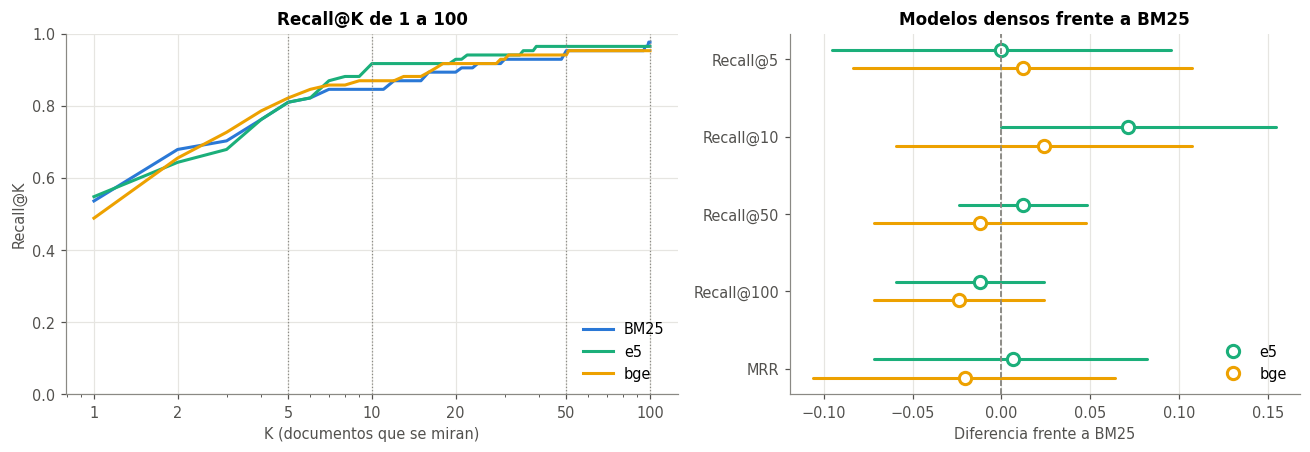

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})

# Izquierda: Recall@K de 1 a 100 para los tres métodos
ks = np.arange(1, K_MAX + 1)
for metodo, r in rankings.items():
    pos = np.array([posicion(rk, rel) or np.inf for rk, rel in zip(r, relevant)])
    ax1.plot(ks, [(pos <= k).mean() for k in ks], color=COLOR[metodo], lw=2, label=metodo)
for k in CORTES:
    ax1.axvline(k, color=GRIS, lw=0.8, ls=':')
ax1.set_xscale('log')
ax1.set_xticks([1, 2, 5, 10, 20, 50, 100], ['1', '2', '5', '10', '20', '50', '100'])
ax1.set(xlabel='K (documentos que se miran)', ylabel='Recall@K', ylim=(0, 1), title='Recall@K de 1 a 100')
ax1.legend(loc='lower right')

# Derecha: diferencia frente a BM25 con su intervalo (relleno: diferencia clara)
for clave, desp in [('e5', 0.12), ('bge', -0.12)]:
    ics = [intervalo(a[clave][m] - a['BM25'][m]) for m in metricas]
    grafica_diferencias(ax2, metricas, ics, COLOR[clave], desp, clave)
ax2.set(xlabel='Diferencia frente a BM25', title='Modelos densos frente a BM25')
ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

- **e5 es el mejor en Recall@10**: 0,917 frente a 0,845 de BM25, es decir, 6 queries más con el documento relevante entre los 10 primeros. La diferencia está justo en el límite de ser clara (su intervalo empieza en 0).
- **Pero no lo coloca más arriba**: en Recall@5 y MRR, e5 y BM25 quedan prácticamente igual, y en Recall@100 e5 queda incluso un poco por debajo (0,964 frente a 0,976, una query). Lo que gana e5 son documentos que BM25 dejaba entre los puestos 11 y 50.
- **bge, el modelo solo en inglés, no mejora a BM25 en nada** y queda por debajo de e5 en todas las métricas. Ser multilingüe no le cuesta nada a e5 con queries en inglés, y además permitirá buscar con afirmaciones en español. **Se elige e5.**
- **Tiempo**: unos 30 ms por query con e5 y unos 25 con bge, frente a 1 ms de BM25 (varía un poco de una ejecución a otra). Es mucho más lento en proporción, pero despreciable frente a lo que tardará el LLM en generar el veredicto (segundos).

Como e5 y BM25 aciertan casi lo mismo en conjunto pero tienen puntos fuertes distintos (sinónimos y paráfrasis frente a nombres raros y exactos), lo natural es comprobar si fallan en queries distintas y, si es así, combinarlos.

### 1.4. ¿Cambia algo la búsqueda aproximada?

El índice HNSW de Chroma no garantiza devolver los vecinos exactos. Para comprobar que la aproximación no afecta a la evaluación, se repite la búsqueda de forma exacta (producto escalar con todos los vectores, que están normalizados) y se comparan las métricas.

In [7]:
for clave in ['e5', 'bge']:
    guardado = colecciones[clave].get(include=['embeddings'])
    E = np.asarray(guardado['embeddings'], dtype=np.float32)
    filas = np.array([fila_de_chunk[cid] for cid in guardado['ids']])
    exactos = []
    for q in queries:
        sims = E @ vector_query(q['query'], clave)[0]
        orden = np.argsort(-sims)[:n_fragmentos(K_MAX)]
        exactos.append(a_documentos(filas[orden], K_MAX))
    iguales = np.mean([r1[:10] == r2[:10] for r1, r2 in zip(exactos, rankings[clave])])
    print(f"{clave}: top 10 idéntico en el {100 * iguales:.0f} % de las queries")
    print(pd.DataFrame({'HNSW (Chroma)': a[clave].mean(), 'exacta': aciertos(exactos, relevant).mean()})
          .round(3).T.to_string(), '\n')

e5: top 10 idéntico en el 61 % de las queries
               Recall@5  Recall@10  Recall@50  Recall@100    MRR
HNSW (Chroma)      0.81      0.917      0.964       0.964  0.651
exacta             0.81      0.917      0.964       0.964  0.657 

bge: top 10 idéntico en el 86 % de las queries
               Recall@5  Recall@10  Recall@50  Recall@100    MRR
HNSW (Chroma)     0.821      0.869       0.94       0.952  0.624
exacta            0.821      0.869       0.94       0.952  0.625 



Las métricas con la búsqueda aproximada de Chroma y con la exacta son prácticamente iguales (el MRR de e5 cambia en la tercera cifra: 0,651 frente a 0,657), así que la aproximación no afecta a la evaluación. Que el top 10 solo sea idéntico en el 61 % de las queries con e5 se debe, con toda probabilidad, a documentos con una similitud casi igual que intercambian su orden; no se ha comprobado uno a uno, pero no cambia en qué puesto queda el documento relevante más que en algún caso aislado.

### 1.5. ¿Fallan en las mismas queries?

e5 y BM25 aciertan casi lo mismo en conjunto, pero tienen puntos fuertes distintos: e5 relaciona textos con palabras distintas y significado parecido, y BM25 acierta con nombres raros y exactos. Si fallan en queries distintas, combinarlos debería acertar más que cada uno por separado.

Para cada query, si cada método pone el documento relevante entre los 10 primeros, y en qué puesto lo deja cuando solo acierta uno de los dos. Además se comprueba si los fallos de e5 tienen que ver con los fragmentos que no le caben enteros (más de 512 *tokens*).

In [8]:
qids = [q['qid'] for q in queries]
pos = {m: [posicion(r, rel) for r, rel in zip(rankings[m], relevant)] for m in ['BM25', 'e5']}
acierta = pd.DataFrame({m: [p is not None and p <= K for p in pos[m]] for m in pos}, index=qids)

etiqueta = {True: 'acierta', False: 'falla'}
print('Documento relevante en el top 10 (número de queries):')
print(pd.crosstab(acierta['BM25'].map(etiqueta), acierta['e5'].map(etiqueta),
                  rownames=['BM25'], colnames=['e5'])
      .reindex(index=['acierta', 'falla'], columns=['acierta', 'falla'], fill_value=0).to_string())

def texto_pos(p):
    return f'>{K_MAX}' if p is None else str(p)

for titulo, filtro in [('Solo acierta BM25', acierta['BM25'] & ~acierta['e5']),
                       ('Solo acierta e5', ~acierta['BM25'] & acierta['e5']),
                       ('No acierta ninguno', ~acierta['BM25'] & ~acierta['e5'])]:
    print(f'\n{titulo}:')
    for i in np.flatnonzero(filtro.values):
        q = queries[i]
        print(f"  {q['qid']} [{q['fuente']}] BM25 {texto_pos(pos['BM25'][i]):>4s}, e5 {texto_pos(pos['e5'][i]):>4s}  {q['query']}")

# ¿Influye que el fragmento de origen no le quepa entero a e5?
fila_origen = [fila_de_chunk[q['source_chunk']] for q in queries]
textos_origen = [MODELOS['e5']['prefijo_doc'] + f"{chunks['titulo'].iat[i]}. {chunks['texto'].iat[i]}"
                 for i in fila_origen]
longitudes = np.array([len(ids) for ids in modelos['e5'].tokenizer(textos_origen)['input_ids']])
cortado = pd.Series(np.where(longitudes > 512, 'se corta', 'cabe entero'), index=qids)
print('\nFragmento de origen de la query con e5:')
print(acierta.assign(origen=cortado).groupby('origen')
      .agg(queries=('e5', 'size'), acierto_e5=('e5', 'mean'), acierto_BM25=('BM25', 'mean')).round(2).to_string())

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (574 > 512). Running this sequence through the model will result in indexing errors


Documento relevante en el top 10 (número de queries):
e5       acierta  falla
BM25                   
acierta       68      3
falla          9      4

Solo acierta BM25:
  q017 [clasicos] BM25    3, e5   22  statue brought to life by Venus and later poets who retold the tale
  q026 [clasicos] BM25    2, e5   35  Trojan prince's wife begs him to stay on the walls so their child is not left fatherless
  q083 [clasicos] BM25    4, e5 >100  wooden horse debate in Greek mythology

Solo acierta e5:
  q004 [wikipedia] BM25   49, e5    2  Locrian town listed in Homer's catalogue of ships, named for its thick woods and later renamed
  q019 [clasicos] BM25   96, e5    4  Apollo's journey through ancient Greece: temples, rivers, and oracular sites established along his path
  q022 [clasicos] BM25 >100, e5    4  the islands of the blessed in classical myth and their echoes in English poetry
  q028 [youtube] BM25   21, e5    7  What is the role of Freyr in Norse mythology and his relationship with 

- **Se complementan.** Los dos aciertan en 68 queries y fallan en 4, pero en 12 acierta solo uno: **9 solo e5 y 3 solo BM25**.
- **Lo que gana e5 es justo lo que fallaba en el Hito 1.** En 6 de sus 9 aciertos exclusivos la query es de los clásicos y describe la escena con otras palabras: *"the islands of the blessed"* (q022), que BM25 no ponía ni entre los 100 primeros, pasa al puesto 4; *"gods flee to Egypt…"* (q084), donde el lematizador dejaba *gods* y *giants* en plural, pasa al 1; y el viaje de Apolo (q019), del 96 al 4. También recupera casos de "otro documento del mismo tema" que BM25 dejaba en los puestos 12 a 16 (q080 Faetón, q082 la cueva del Sueño, q092 Diomedes).
- **BM25 sigue ganando en 3 queries**, las tres de los clásicos. En q083 (*"wooden horse debate…"*) e5 ni siquiera pone el documento entre los 100 primeros.
- **Fallan los dos en 4**: q016 y q078, que ya eran los fallos más lejanos del Hito 1 (vocabulario muy distinto al del texto), y q032 y q034, en los que gana otro documento del mismo tema (puestos 16 a 50).
- **Los fragmentos cortados no explican nada aquí**: solo 1 de los 84 fragmentos de origen no le cabe entero a e5, y además lo acierta. Afectan al 5,7 % del corpus, pero no a la evaluación, así que no se añade el segundo vector por ahora; queda como limitación.

### 1.6. Búsqueda híbrida

Para combinar BM25 y e5 se usa la **fusión por rangos recíprocos** (*Reciprocal Rank Fusion*, RRF): cada fragmento suma, por cada método que lo recupera, una puntuación que solo depende de su puesto,

$$\text{RRF}(f) = \sum_{m \in \{\text{BM25},\ \text{e5}\}} \frac{1}{c + \text{puesto}_m(f)}$$

y se ordena por esa suma. Tiene dos ventajas: no hace falta poner en la misma escala las puntuaciones de BM25 y la similitud coseno, que no tienen nada que ver, y premia a los fragmentos que los dos métodos colocan arriba. Se usa $c = 60$, el valor propuesto por sus autores (Cormack et al., 2009), sin ajustarlo con nuestras queries para no inflar los resultados.

La fusión se hace con los **fragmentos** (los 2.000 primeros de cada método), porque son lo que el sistema pasará al LLM; después se pasa a documentos igual que en el resto de la evaluación.

In [9]:
N_FRAG = n_fragmentos(K_MAX)
RRF_C = 60

def filas_bm25(tokens_query, n=N_FRAG):
    if not tokens_query:
        return []
    filas, _ = bm25.retrieve([tokens_query], k=n, show_progress=False)
    return list(filas[0])

def filas_denso(texto, clave='e5', n=N_FRAG):
    res = colecciones[clave].query(query_embeddings=vector_query(texto, clave).tolist(),
                                   n_results=n, include=['distances'])
    return [fila_de_chunk[cid] for cid in res['ids'][0]]

def fusion_rrf(*listas, c=RRF_C):
    # Cada fragmento suma 1 / (c + puesto) por cada lista en la que aparece
    puntos = {}
    for lista in listas:
        for puesto, fila in enumerate(lista, 1):
            puntos[fila] = puntos.get(fila, 0) + 1 / (c + puesto)
    return sorted(puntos, key=puntos.get, reverse=True)

def retrieve_hibrida(texto, tokens_query, k=K):
    return a_documentos(fusion_rrf(filas_bm25(tokens_query), filas_denso(texto)), k)

inicio = time.perf_counter()
rankings['híbrida'] = [retrieve_hibrida(q['query'], t, k=K_MAX) for q, t in zip(queries, q_tokens)]
tiempos['híbrida'] = (time.perf_counter() - inicio) / len(queries)
a['híbrida'] = aciertos(rankings['híbrida'], relevant)

tabla = pd.DataFrame({m: {x: texto_ic(*intervalo(a[m][x])) for x in metricas} for m in ['BM25', 'e5', 'híbrida']})
for base in ['BM25', 'e5']:
    tabla[f'híbrida − {base}'] = {x: texto_ic(*intervalo(a['híbrida'][x] - a[base][x])) for x in metricas}
print(f"{len(queries)} queries. Media [intervalo bootstrap del 95 %]\n")
print(tabla.to_string())
print('\nTiempo medio por query:', {m: f'{1000 * tiempos[m]:.0f} ms' for m in ['BM25', 'e5', 'híbrida']})

84 queries. Media [intervalo bootstrap del 95 %]

                            BM25                    e5               híbrida         híbrida − BM25           híbrida − e5
Recall@5    0.810 [0.726, 0.893]  0.810 [0.726, 0.893]  0.845 [0.774, 0.917]  0.036 [-0.024, 0.095]  0.036 [-0.060, 0.131]
Recall@10   0.845 [0.762, 0.917]  0.917 [0.857, 0.964]  0.917 [0.857, 0.976]   0.071 [0.012, 0.131]  0.000 [-0.060, 0.060]
Recall@50   0.952 [0.905, 0.988]  0.964 [0.917, 1.000]  0.976 [0.940, 1.000]   0.024 [0.000, 0.060]   0.012 [0.000, 0.036]
Recall@100  0.976 [0.940, 1.000]  0.964 [0.917, 1.000]  0.976 [0.940, 1.000]  0.000 [-0.036, 0.036]   0.012 [0.000, 0.036]
MRR         0.645 [0.561, 0.733]  0.651 [0.566, 0.736]  0.729 [0.650, 0.807]   0.085 [0.041, 0.132]   0.078 [0.014, 0.147]

Tiempo medio por query: {'BM25': '1 ms', 'e5': '38 ms', 'híbrida': '35 ms'}


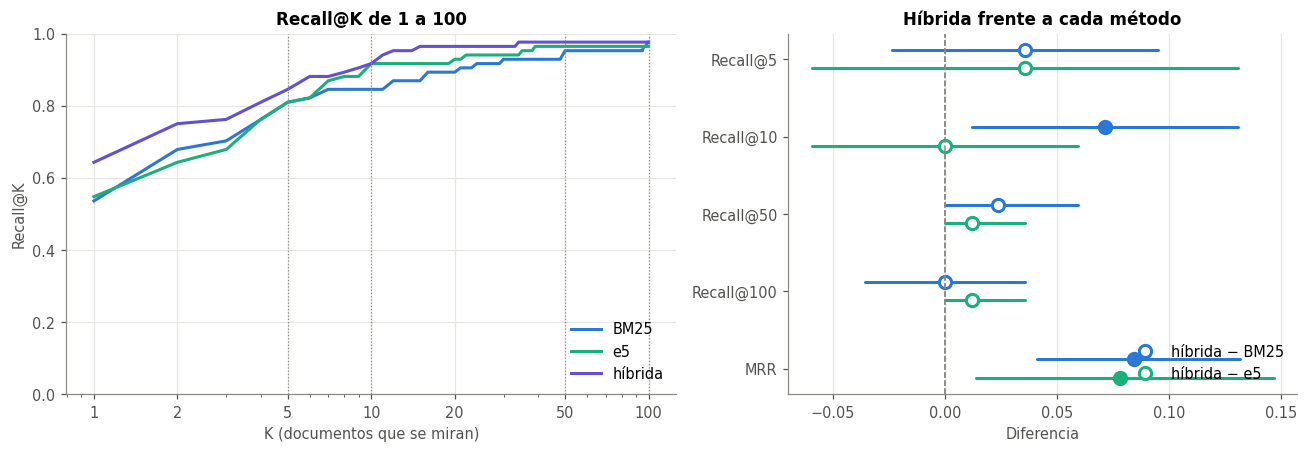

In [10]:
COLOR['híbrida'] = '#6250d6'
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.2, 1]})

# Izquierda: Recall@K de 1 a 100
for metodo in ['BM25', 'e5', 'híbrida']:
    p = np.array([posicion(rk, rel) or np.inf for rk, rel in zip(rankings[metodo], relevant)])
    ax1.plot(ks, [(p <= k).mean() for k in ks], color=COLOR[metodo], lw=2, label=metodo)
for k in CORTES:
    ax1.axvline(k, color=GRIS, lw=0.8, ls=':')
ax1.set_xscale('log')
ax1.set_xticks([1, 2, 5, 10, 20, 50, 100], ['1', '2', '5', '10', '20', '50', '100'])
ax1.set(xlabel='K (documentos que se miran)', ylabel='Recall@K', ylim=(0, 1), title='Recall@K de 1 a 100')
ax1.legend(loc='lower right')

# Derecha: la híbrida frente a cada método por separado (relleno: diferencia clara)
for base, desp in [('BM25', 0.12), ('e5', -0.12)]:
    ics = [intervalo(a['híbrida'][m] - a[base][m]) for m in metricas]
    grafica_diferencias(ax2, metricas, ics, COLOR[base], desp, f'híbrida − {base}')
ax2.set(xlabel='Diferencia', title='Híbrida frente a cada método')
ax2.legend(loc='lower right')
plt.tight_layout()
plt.show()

- **La búsqueda híbrida es la mejor en todo**: Recall@10 de 0,917 (como e5 y claramente por encima de BM25, +0,071) y, sobre todo, **MRR de 0,729**, frente a 0,645 de BM25 y 0,651 de e5. Las dos diferencias de MRR son claras: +0,085 [0,041; 0,132] y +0,078 [0,014; 0,147].
- **La ganancia está en la posición**: al sumar los dos rankings, el documento que los dos métodos ven arriba sube, y los aciertos exclusivos de cada uno no se pierden. En Recall@100 queda igual que BM25 (0,976), el mejor de los dos.
- **Coste**: unos 35 ms por query, prácticamente lo mismo que e5 solo.
- El parámetro $c = 60$ no se ha ajustado con nuestras queries, así que esta mejora no es fruto de afinar con los mismos datos con los que se evalúa.

**Decisión: el sistema RAG recupera con la búsqueda híbrida BM25 + e5.**

## 2. Generación

### 2.1. El verificador

Ante una afirmación, el sistema hace tres pasos:

1. **Busca pruebas** con la búsqueda híbrida de la sección 1.6: los 5 mejores fragmentos, como mucho 2 del mismo documento, para que las pruebas no salgan todas del mismo texto.
2. **Pide el veredicto al LLM.** Le pasa los fragmentos numerados del [1] al [5], cada uno con su título y su fuente, y le pide un JSON con el veredicto (*true*, *false* o *not_enough_info*), una explicación breve y los números de los fragmentos que la apoyan.
3. **Monta la respuesta para el usuario**: el veredicto, la explicación y las fuentes citadas con su enlace y el principio del fragmento. Los datos para citar (título, fuente, sección, URL, segundo del vídeo) salen de Chroma, que los guarda junto a cada vector.

Las decisiones principales:

- **Solo con las pruebas.** El prompt pide usar únicamente los fragmentos, no lo que el LLM sepa por su cuenta: el sistema solo afirma lo que puede citar. Para decir *falso* hace falta que un fragmento diga lo contrario; que un dato no aparezca no basta, eso es *sin información*.
- **Cuando no hay información, el sistema no responde.** El usuario recibe una frase fija ("no he encontrado información en las fuentes…") y no la explicación del LLM, que podría rellenar con lo que sabe.
- **Idioma.** Se detecta el idioma de la afirmación con `langdetect` y se le dice al LLM en qué idioma escribir la explicación. El resto del prompt, los fragmentos y el JSON van en inglés, que es lo que mejor manejan estos modelos. La búsqueda no cambia con afirmaciones en español: e5 es multilingüe, y BM25 aprovecha al menos los nombres propios.
- **Salida en JSON** (opción `format: json` del servidor), para leer el veredicto y las citas sin ambigüedad y poder evaluarlos automáticamente.
- **Temperatura 0**, para que las respuestas sean reproducibles, y una ventana de contexto de 8.192 *tokens* (`num_ctx`): los 5 fragmentos ocupan unos 2.000 y no deben cortarse.
- **LLM**: `llama3.1:8b`, del servidor de la UC3M. En la sección 3 se compara con `qwen3:8b`.

Primero, la búsqueda de pruebas. Para probarla se usan afirmaciones del conjunto de evaluación, que se describe en la sección 3; aquí, una afirmación falsa en inglés y su traducción al español.

In [11]:
import re
import textwrap

import requests
import urllib3
from langdetect import DetectorFactory, detect_langs
from clasifica_wikipedia import URL, leer_clave

urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)
CLAVE = leer_clave()               # del archivo .env, que no se sube a GitHub
MODELO = 'llama3.1:8b'
N_PRUEBAS, MAX_POR_DOC = 5, 2

afirmaciones = {a['aid']: a for a in leer_jsonl(DATOS / 'afirmaciones.jsonl')}

def recupera_pruebas(afirmacion, n=N_PRUEBAS, max_por_doc=MAX_POR_DOC):
    # Búsqueda híbrida (BM25 + e5 con RRF), como en la sección 1.6. Basta con fusionar
    # los 200 primeros fragmentos de cada método para quedarse con los 5 mejores.
    tokens_q = [w for w in preparar([afirmacion])[0] if w in vocabulario]
    filas = fusion_rrf(filas_bm25(tokens_q, n=200), filas_denso(afirmacion, n=200))
    elegidas, por_doc = [], {}
    for fila in filas:
        d = doc_de_fila[fila]
        if por_doc.get(d, 0) < max_por_doc:
            elegidas.append(fila)
            por_doc[d] = por_doc.get(d, 0) + 1
            if len(elegidas) == n:
                break
    # El texto y los datos para citar se leen de Chroma
    ids = [chunks['chunk_id'].iat[f] for f in elegidas]
    res = colecciones['e5'].get(ids=ids, include=['documents', 'metadatas'])
    guardado = {i: {'texto': t, **m} for i, t, m in zip(res['ids'], res['documents'], res['metadatas'])}
    return [{'chunk_id': i, **guardado[i]} for i in ids]

for aid in ['a002', 'a002_es']:
    a = afirmaciones[aid]
    inicio = time.perf_counter()
    pruebas = recupera_pruebas(a['afirmacion'])
    print(f"{aid} ({time.perf_counter() - inicio:.2f} s): {a['afirmacion']}")
    for n, p in enumerate(pruebas, 1):
        marca = '  <- documento de origen' if p['doc_id'] in a['relevant_ids'] else ''
        print(f"   [{n}] {p['chunk_id']:28s} {p['titulo']}{marca}")
    print()

a002 (0.17 s): Opus I, king of the Epeians, was the son of Poseidon by Protogeneia, daughter of Deucalion.
   [1] wiki_24959971_c01            Opus (mythology)  <- documento de origen
   [2] wiki_909474_c01              Protogeneia
   [3] wiki_58272592_c01            Deucalion (mythology)
   [4] wiki_9854465_c01             Aethlius
   [5] wiki_83164_c01               Metion

a002_es (0.04 s): Opus I, rey de los epeos, fue hijo de Poseidón y de Protogenia, hija de Deucalión.
   [1] wiki_24959971_c01            Opus (mythology)  <- documento de origen
   [2] wiki_909474_c01              Protogeneia
   [3] apolodoro_07_c02             Apollodorus, Library 1.7
   [4] wiki_54075838_c01            Thyia (daughter of Deucalion)
   [5] wiki_58272592_c01            Deucalion (mythology)



Ahora el prompt y la llamada al LLM. La función `verificar` junta los tres pasos y devuelve todo lo necesario para mostrar la respuesta y para evaluarla después: el veredicto, la explicación, las citas, las pruebas y el tiempo de cada paso. Si el LLM devuelve una cita que no existe (un número fuera de 1-5), se descarta; si no devuelve un JSON válido tras tres intentos, el veredicto queda vacío y cuenta como fallo.

In [12]:
PROMPT = """You are a fact-checker for Greek, Roman and Norse mythology.
Decide whether the claim is true or false using ONLY the evidence passages below. Do not use your own knowledge.

- "true": the passages state what the claim says.
- "false": the passages state something that contradicts the claim (for example, a different person, place, relationship or event).
- "not_enough_info": the passages neither confirm nor contradict the claim, for example because they are about something else or do not mention the key detail. If a detail is simply not mentioned, the answer is "not_enough_info", not "false".

Evidence passages:

{pruebas}

Claim: {afirmacion}

Write a short explanation (one or two sentences) in {idioma}, based only on the passages.
In "citations", give the numbers of the passages that support your verdict (an empty list for "not_enough_info").
Answer only with JSON: {{"verdict": "true" or "false" or "not_enough_info", "explanation": "...", "citations": [...]}}"""

FUENTE_LLM = {'clasicos': 'classical text', 'whe': 'World History Encyclopedia',
              'wikipedia': 'Wikipedia', 'youtube': 'YouTube video transcript'}
VEREDICTO = {'true': 'verdadero', 'false': 'falso', 'not_enough_info': 'sin_informacion'}
NOMBRE_IDIOMA = {'es': 'Spanish', 'en': 'English'}
DetectorFactory.seed = 0           # sin semilla, langdetect puede dar resultados distintos cada vez

def detecta_idioma(texto):
    # El sistema contesta en español o en inglés: se elige el más probable de los dos
    try:
        prob = {l.lang: l.prob for l in detect_langs(texto)}
    except Exception:
        return 'en'
    return 'es' if prob.get('es', 0) > prob.get('en', 0) else 'en'

def llamar_llm(prompt, modelo, intentos=3):
    # Devuelve el JSON del LLM. Si el servidor no responde tras varios intentos, devuelve None
    # (se volverá a pedir); si responde con un JSON roto, devuelve {} (es un fallo del modelo:
    # con temperatura 0 saldría igual al repetirlo).
    datos = {'model': modelo, 'prompt': prompt, 'stream': False, 'format': 'json',
             'options': {'temperature': 0, 'num_ctx': 8192}}
    if modelo.startswith('qwen3'):
        datos['think'] = False     # si no, qwen3 "piensa en voz alta" antes de responder
    for intento in range(intentos):
        try:
            r = requests.post(URL, json=datos, headers={'X-API-KEY': CLAVE}, verify=False, timeout=180)
            r.raise_for_status()
            texto = r.json()['response']
            break
        except Exception as e:
            if intento == intentos - 1:
                print(f'  ERROR del servidor: {e}')
                return None
            time.sleep(5)
    try:
        return json.loads(texto)
    except json.JSONDecodeError:
        print(f'  JSON no válido del modelo: {texto[:80]!r}…')
        return {}

def lee_citas(citas, n_pruebas):
    # Acepta 1, "1" o "[1]"; descarta los números que no son de ningún fragmento
    numeros = {int(x) for c in (citas if isinstance(citas, list) else [citas]) for x in re.findall(r'\d+', str(c))}
    return sorted(n for n in numeros if 1 <= n <= n_pruebas)

def normaliza(texto):
    return ' '.join(texto.lower().split())

def verificar(afirmacion, modelo=MODELO, prompt_base=PROMPT):
    idioma = detecta_idioma(afirmacion)
    inicio = time.perf_counter()
    pruebas = recupera_pruebas(afirmacion)
    t_busqueda = time.perf_counter() - inicio

    texto_pruebas = '\n\n'.join(f'[{n}] "{p["titulo"]}" ({FUENTE_LLM[p["fuente"]]})\n{p["texto"]}'
                                for n, p in enumerate(pruebas, 1))
    prompt = prompt_base.format(pruebas=texto_pruebas, afirmacion=afirmacion, idioma=NOMBRE_IDIOMA[idioma])
    inicio = time.perf_counter()
    respuesta = llamar_llm(prompt, modelo)
    t_llm = time.perf_counter() - inicio

    error_llm = respuesta is None          # el servidor no respondió tras tres intentos
    respuesta = respuesta if isinstance(respuesta, dict) else {}
    veredicto = veredicto_llm = VEREDICTO.get(str(respuesta.get('verdict', '')).strip().lower())
    # Frase de los fragmentos que apoya el veredicto: solo la pide el prompt de la sección 2.3
    prueba = str(respuesta.get('evidence', '')).strip().strip('"«»')
    if 'evidence' in respuesta and not prueba and veredicto in ('verdadero', 'falso'):
        veredicto = 'sin_informacion'      # sin una frase que lo apoye, no hay veredicto
    citas = lee_citas(respuesta.get('citations', []), len(pruebas)) if veredicto != 'sin_informacion' else []
    return {'afirmacion': afirmacion, 'idioma': idioma, 'modelo': modelo, 'veredicto': veredicto, 'veredicto_llm': veredicto_llm, 'error_llm': error_llm,
            'explicacion': str(respuesta.get('explanation', '')), 'citas': citas,
            'prueba': prueba, 'prueba_literal': bool(prueba) and normaliza(prueba) in normaliza(texto_pruebas),
            'pruebas': pruebas, 't_busqueda': t_busqueda, 't_llm': t_llm}

Por último, la respuesta que ve el usuario, en el idioma de la afirmación. De cada fuente citada se muestra el título, la fuente, la sección y el enlace (en los vídeos, al segundo exacto) y el principio del fragmento.

In [13]:
TEXTOS = {
    'es': {'verdadero': 'VERDADERO', 'falso': 'FALSO', 'sin_informacion': 'SIN INFORMACIÓN', None: 'ERROR',
           'afirmacion': 'Afirmación', 'veredicto': 'Veredicto', 'fuentes': 'Fuentes', 'prueba': 'Prueba',
           'sin_info': 'No he encontrado información en las fuentes para confirmar o desmentir esta afirmación.',
           'sin_citas': '(El modelo no ha citado ningún fragmento.)',
           'error': 'No se ha podido obtener una respuesta del modelo.',
           'fuente': {'clasicos': 'texto clásico', 'whe': 'World History Encyclopedia',
                      'wikipedia': 'Wikipedia', 'youtube': 'YouTube'}},
    'en': {'verdadero': 'TRUE', 'falso': 'FALSE', 'sin_informacion': 'NOT ENOUGH INFORMATION', None: 'ERROR',
           'afirmacion': 'Claim', 'veredicto': 'Verdict', 'fuentes': 'Sources', 'prueba': 'Evidence',
           'sin_info': 'I have not found information in the sources to confirm or refute this claim.',
           'sin_citas': '(The model did not cite any passage.)',
           'error': 'Could not get an answer from the model.',
           'fuente': {'clasicos': 'classical text', 'whe': 'World History Encyclopedia',
                      'wikipedia': 'Wikipedia', 'youtube': 'YouTube'}},
}

def enlace(p):
    url = p.get('url', '')
    if p['fuente'] == 'youtube' and url and p.get('segundo') != '':
        url += ('&' if '?' in url else '?') + f"t={p['segundo']}s"
    return url

def formatea(r, palabras=50):
    t = TEXTOS[r['idioma']]
    lineas = [f"{t['afirmacion']}: {r['afirmacion']}", f"{t['veredicto']}: {t[r['veredicto']]}"]
    if r['veredicto'] is None:
        lineas.append(t['error'])
    elif r['veredicto'] == 'sin_informacion':
        lineas.append(t['sin_info'])
    else:
        lineas.append(textwrap.fill(r['explicacion'], 100))
        if r.get('prueba'):
            lineas.append(textwrap.fill(f"{t['prueba']}: «{r['prueba']}»", 100, subsequent_indent=' ' * 4))
        lineas.append(f"\n{t['fuentes']}:")
        if not r['citas']:
            lineas.append('  ' + t['sin_citas'])
        for n in r['citas']:
            p = r['pruebas'][n - 1]
            seccion = f", {p['seccion']}" if p.get('seccion') and p['fuente'] != 'youtube' else ''
            lineas.append(f"  [{n}] {p['titulo']} ({t['fuente'][p['fuente']]}{seccion}) {enlace(p)}")
            trozo = ' '.join(p['texto'].split()[:palabras])
            lineas.append(textwrap.fill(f'«{trozo}…»', 100, initial_indent=' ' * 6, subsequent_indent=' ' * 6))
    return '\n'.join(lineas)

### 2.2. Ejemplos

Cinco afirmaciones del conjunto de evaluación, una de cada caso: una verdadera y su versión falsa en inglés, la falsa traducida al español, un hecho de otra mitología (Gilgamesh, mesopotámica) y un detalle inventado en español. Encima de cada respuesta, el veredicto correcto y el tiempo de cada paso; en los casos sin información se enseña también la explicación del LLM, que el usuario no ve.

In [14]:
for aid in ['a001', 'a002', 'a002_es', 'a172', 'a198_es']:
    a = afirmaciones[aid]
    r = verificar(a['afirmacion'])
    print(f"── {aid} · correcto: {a['etiqueta']} · búsqueda {r['t_busqueda']:.2f} s, LLM {r['t_llm']:.1f} s ──")
    print(formatea(r))
    if r['veredicto'] == 'sin_informacion':
        print(f"  (Explicación del LLM, no se muestra: {r['explicacion']})")
    print()

── a001 · correcto: verdadero · búsqueda 0.03 s, LLM 68.0 s ──
Claim: Opus I, king of the Epeians, was the son of Zeus by Protogeneia, daughter of Deucalion.
Verdict: TRUE
The passages confirm that Opus I was the son of Zeus by Protogeneia, who is described as the
daughter of Deucalion.

Sources:
  [1] Opus (mythology) (Wikipedia) https://en.wikipedia.org/wiki/Opus_(mythology)
      «In Greek mythology, Opus (Ancient Greek: Ὀπόεις) may refer to the following characters: Opus
      I, king of the Epeians and son of Zeus by Protogeneia, daughter of Deucalion. Opus was the
      father of Cambyse or Protogeneia who was carried off by Zeus to Mt. Maenalus in Arcadia where
      she bore…»

── a002 · correcto: falso · búsqueda 0.09 s, LLM 65.9 s ──
Claim: Opus I, king of the Epeians, was the son of Poseidon by Protogeneia, daughter of Deucalion.
Verdict: FALSE
The passages state that Opus I was the son of Zeus by Protogeneia, daughter of Deucalion.

Sources:
  [1] Opus (mythology) (Wikipedi

- **La búsqueda funciona también en español.** Con la afirmación falsa y su traducción, el documento de origen (*Opus*) sale el primero en los dos casos, y 3 de los 5 fragmentos coinciden. e5 relaciona el español con el inglés sin traducir, y BM25 aprovecha los nombres propios.
- **Verdaderas y falsas: bien.** Las tres aciertan, citan el fragmento de *Opus* y la explicación dice justo el dato cambiado (Zeus y no Poseidón). Con la afirmación en español, la explicación sale en español.
- **Sin información: mal.** Las dos salen *falso*, aunque la propia explicación del LLM dice que los fragmentos **no mencionan** lo que dice la afirmación: confunde "no aparece" con "es falso", justo lo que el prompt pedía evitar. Además cita fragmentos que no prueban nada (*Master of Animals*, *Iphigenia*). Es el error más grave que puede cometer el sistema: desmentir algo que no puede comprobar.
- **Tiempo**: la búsqueda tarda menos de 0,1 s; el LLM, entre 1 y 7 s.

### 2.3. Ajuste del prompt

Dos cambios para que el LLM no diga *falso* cuando no hay pruebas:

1. **Primero la prueba y después el veredicto.** Se le pide que, antes de decidir, copie en un campo `evidence` la frase de los fragmentos que habla del mismo dato que la afirmación, o que lo deje vacío si no hay ninguna. El LLM escribe la respuesta en orden, así que el veredicto se apoya en lo que acaba de copiar; con el campo vacío, lo coherente es *not_enough_info*. Las instrucciones van ahora en pasos y después de las pruebas, para que las tenga más cerca al responder.
2. **Una regla fija en el código: sin prueba no hay veredicto.** Si el LLM dice *verdadero* o *falso* pero deja la prueba vacía, el veredicto pasa a *sin información*.

Además, se comprueba si la frase copiada aparece de verdad en los fragmentos: en la evaluación servirá para medir si el LLM se inventa las pruebas. La frase también se le enseña al usuario.

El prompt se ajusta solo con estos cinco ejemplos; si funciona bien con las 250 afirmaciones de la sección 3, el ajuste no se ha hecho a medida de ellos.

In [15]:
PROMPT_V2 = """You are a fact-checker for Greek, Roman and Norse mythology.
Decide whether the claim is true or false using ONLY the evidence passages below. Do not use your own knowledge.

Evidence passages:

{pruebas}

Claim: {afirmacion}

Follow these steps:
1. Find the key detail of the claim (who did what, whose son, which place...).
2. Look for a sentence in the passages about that same detail and copy it exactly in "evidence". If no passage talks about that detail, leave "evidence" empty (""), even if the passages mention the same characters.
3. Decide the verdict:
   - "true": the evidence says the same as the claim.
   - "false": the evidence says something incompatible with the claim (for example, a different father, place or event).
   - "not_enough_info": "evidence" is empty. A detail that is not mentioned is "not_enough_info", never "false".
4. Write a short explanation (one or two sentences) in {idioma}, based only on the passages.
5. In "citations", give the numbers of the passages the evidence comes from (an empty list for "not_enough_info").

Answer only with JSON: {{"evidence": "...", "verdict": "true" or "false" or "not_enough_info", "explanation": "...", "citations": [...]}}"""

for aid in ['a001', 'a002', 'a002_es', 'a172', 'a198_es']:
    a = afirmaciones[aid]
    r = verificar(a['afirmacion'], prompt_base=PROMPT_V2)
    print(f"── {aid} · correcto: {a['etiqueta']} · búsqueda {r['t_busqueda']:.2f} s, LLM {r['t_llm']:.1f} s"
          f" · prueba literal: {r['prueba_literal']} ──")
    print(formatea(r))
    if r['veredicto'] == 'sin_informacion':
        print(f"  (Explicación del LLM, no se muestra: {r['explicacion']})")
    print()

── a001 · correcto: verdadero · búsqueda 0.10 s, LLM 66.5 s · prueba literal: True ──
Claim: Opus I, king of the Epeians, was the son of Zeus by Protogeneia, daughter of Deucalion.
Verdict: TRUE
According to passage [1], Opus I is indeed the son of Zeus by Protogeneia, who is the daughter of
Deucalion.
Evidence: «Opus I, king of the Epeians and son of Zeus by Protogeneia, daughter of Deucalion.»

Sources:
  [1] Opus (mythology) (Wikipedia) https://en.wikipedia.org/wiki/Opus_(mythology)
      «In Greek mythology, Opus (Ancient Greek: Ὀπόεις) may refer to the following characters: Opus
      I, king of the Epeians and son of Zeus by Protogeneia, daughter of Deucalion. Opus was the
      father of Cambyse or Protogeneia who was carried off by Zeus to Mt. Maenalus in Arcadia where
      she bore…»

── a002 · correcto: falso · búsqueda 0.08 s, LLM 66.1 s · prueba literal: True ──
Claim: Opus I, king of the Epeians, was the son of Poseidon by Protogeneia, daughter of Deucalion.
Verdict: FALS

- **Con el prompt nuevo aciertan los cinco.** Las dos afirmaciones sin información salen ahora *sin información*, y el usuario recibe la frase fija en su idioma.
- **Las verdaderas y falsas siguen bien**, y ahora la respuesta enseña la frase exacta del fragmento que lo prueba (*"son of Zeus by Protogeneia"*). En las tres, la frase está de verdad en el fragmento citado: no se la inventa.
- **Un detalle a vigilar**: en a001 la explicación empieza con *"According to Greek mythology…"*, como si hablara de lo que sabe y no de los fragmentos. El veredicto y la prueba son correctos, pero lo tendremos en cuenta al revisar la evaluación.
- Con cinco ejemplos no se puede saber si los casos sin información los ha resuelto el LLM o la regla del código. Para separarlo, `verificar` guarda también el veredicto original del LLM (`veredicto_llm`), y en la evaluación se cuenta cuántas veces actúa la regla.

**El sistema usa este prompt (`PROMPT_V2`)** en la evaluación de la sección 3.

## 3. Evaluación de la generación

### 3.1. Las afirmaciones de evaluación

Las 84 queries del Hito 1 sirven para evaluar la búsqueda, pero no los veredictos: describen un pasaje, no afirman nada que sea verdadero o falso. Para evaluar la generación hace falta un conjunto de **afirmaciones con su veredicto correcto conocido**. Se ha creado a partir de las mismas queries, en tres pasos:

1. **Generación con el LLM** (`src/genera_afirmaciones.py`, con `llama3.1:8b`):
   - **Verdaderas y falsas.** Para el fragmento de origen de cada query, el LLM escribe un hecho que el fragmento afirma (*verdadera*) y el mismo hecho con **un solo dato cambiado** (*falsa*), de modo que el fragmento la desmiente. Como cada una sale de un fragmento conocido, se sabe qué documento debería encontrar la búsqueda y citar el sistema.
   - **Sin información**, de dos tipos: 20 hechos de **otras mitologías** (egipcia, azteca, hindú…, 2 de cada una de 10), que el corpus no cubre, y 20 **detalles inventados** sobre personajes de nuestras mitologías (un objeto, un lugar o un compañero con un nombre inventado), que ningún texto menciona.
2. **Revisión a mano**, una por una, junto a su fragmento (`data/revision_afirmaciones.csv`): cada afirmación se mantiene, se corrige o se descarta, con el motivo. La revisión se hizo con ayuda de un asistente de IA y la comprobamos nosotros (ver el uso de IA en `MILESTONE_2.md`).
3. **Traducción al español** (`src/crea_afirmaciones.py`): las dos afirmaciones de 20 queries elegidas al azar y 10 sin información, para comprobar que el sistema contesta en el idioma de la afirmación y comparar la misma afirmación en los dos idiomas. Las traducciones del LLM también se revisaron a mano (`data/traducciones_afirmaciones.csv`).

Este es el prompt con el que se generaron las verdaderas y las falsas:

In [16]:
import genera_afirmaciones
print(genera_afirmaciones.PROMPT_FRAGMENTO)

You will receive a passage from a collection about Greek, Roman and Norse mythology.
Write two short factual claims (8-25 words each) to test a fact-checking system:

1. "true_claim": one specific fact that the passage clearly states. Choose a fact that is central to the passage, not a minor aside.
2. "false_claim": the same claim with exactly ONE detail changed (a name, a relationship, a place, a number or an action), so that the passage clearly contradicts it. Keep it plausible: replace the detail with another one of the same kind from the same mythology.
3. "change": what you changed, in a few words.

Rules for both claims:
- Self-contained: name the characters, places or works explicitly. No pronouns without a clear referent, and never "the passage" or "this text".
- Use your own words: do not copy sentences from the passage.

Answer only with JSON: {{"true_claim": "...", "false_claim": "...", "change": "..."}}

Passage (from "{titulo}"):
{texto}


La revisión: qué se hizo con cada tipo de afirmación y por qué. Los motivos están escritos a mano en el CSV; aquí se agrupan por palabras clave.

In [17]:
revision = pd.read_csv(DATOS / 'revision_afirmaciones.csv')
print(f'{len(revision)} afirmaciones candidatas\n')
print(pd.crosstab(revision['etiqueta'], revision['decision'], margins=True, margins_name='total').to_string())

# Agrupar los motivos (en este orden: el primero que encaja)
TIPOS_MOTIVO = [
    ('se ajusta a su pareja (la otra afirmación de la query)', r'Se adapta|Va con'),
    ('podría estar en el corpus o chocar con el mito',        r'Riesgo|Podía chocar|real del mito'),
    ('dato equivocado',                                       r'Error de contenido|Dato incorrecto|Describe mal|Dato impreciso|Contradice el mito|lo inventa|equivocado'),
    ('la falsa no la desmiente el fragmento',                 r'desmiente|sería verdadera'),
    ('la falsa cambiaba más de un dato',                      r'dos datos|tres datos|varios datos'),
    ('nombre mal escrito (sobre todo, subtítulos de YouTube)', r'subtítulos|Errata|mal transcrit'),
]
def tipo_motivo(motivo):
    for tipo, patron in TIPOS_MOTIVO:
        if re.search(patron, motivo):
            return tipo
    return 'poco clara o mal formulada'

cambiadas = revision[revision['decision'] != 'mantener'].copy()
cambiadas['motivo_agrupado'] = cambiadas['motivo'].map(tipo_motivo)
print('\nMotivos de las corregidas y descartadas:')
motivos = pd.crosstab(cambiadas['motivo_agrupado'], cambiadas['decision'])
motivos['total'] = motivos.sum(axis=1)
motivos = motivos.sort_values('total', ascending=False)
motivos.loc['total'] = motivos.sum()
print(motivos.to_string())

print('\nAlgunos errores del LLM corregidos:')
for aid in ['a046', 'a122', 'a117', 'a195']:
    r = revision.set_index('aid').loc[aid]
    print(f"\n  {aid} ({r['etiqueta']}) - {r['motivo']}\n     antes:   {r['afirmacion']}\n     después: {r['afirmacion_final']}")

208 afirmaciones candidatas

decision         descartar  editar  mantener  total
etiqueta                                           
falso                    2      41        41     84
sin_informacion          4       7        29     40
verdadero                2      26        56     84
total                    8      74       126    208

Motivos de las corregidas y descartadas:
decision                                                descartar  editar  total
motivo_agrupado                                                                 
se ajusta a su pareja (la otra afirmación de la query)          2      19     21
poco clara o mal formulada                                      0      14     14
la falsa cambiaba más de un dato                                0      14     14
dato equivocado                                                 3       9     12
la falsa no la desmiente el fragmento                           1       8      9
nombre mal escrito (sobre todo, subtítulos de YouT

El conjunto final, después de la revisión y la traducción, con un ejemplo de cada tipo:

In [18]:
conjunto = pd.DataFrame(afirmaciones.values())
print(f'{len(conjunto)} afirmaciones\n')
print(pd.crosstab([conjunto['etiqueta'], conjunto['origen']], conjunto['idioma'], margins=True, margins_name='total').to_string())

print('\nEjemplos:')
for aid in ['a003', 'a004', 'a175', 'a204', 'a175_es']:
    a = afirmaciones[aid]
    print(f"  {aid:8s} {a['etiqueta']:16s} {a['origen']:15s} {a['afirmacion']}")

250 afirmaciones

idioma                           en  es  total
etiqueta        origen                        
falso           fragmento        82  20    102
sin_informacion inventada        20   5     25
                otra_mitologia   16   5     21
verdadero       fragmento        82  20    102
total                           200  50    250

Ejemplos:
  a003     verdadero        fragmento       According to Plutarch's story, Thamus proclaimed at Palodes that the great god Pan is dead.
  a004     falso            fragmento       According to Plutarch's story, Dionysus proclaimed at Palodes that the great god Pan is dead.
  a175     sin_informacion  otra_mitologia  Huitzilopochtli, the Aztec sun god, was said to have guided his people out of the mythical city of Aztlan.
  a204     sin_informacion  inventada       Thor once used his hammer to smash the ice gates of Frosthaven, where he met the winter spirit, Aethera.
  a175_es  sin_informacion  otra_mitologia  Se decía que Huitzilopoc

- **El LLM sirve para empezar, pero no basta solo.** De las 208 candidatas se mantuvieron 126 (61 %); 74 se corrigieron y 8 se descartaron.
- **Las falsas son las que más fallan**: hubo que corregir 41 de 84, frente a 26 de 84 verdaderas. Lo más habitual es que cambie más de un dato (14) o que el fragmento no llegue a desmentir la falsa (9). En algún caso la "falsa" era en realidad verdadera, como cambiar Neptuno por Poseidón, que son el mismo dios. Otras 21 correcciones solo ajustan una afirmación a su pareja corregida.
- **En 12 el LLM entendió mal el fragmento** (por ejemplo, la peste de Egina convertida en la de Tebas), y en 7 había nombres mal escritos, casi todos de los subtítulos automáticos de YouTube.
- **En las sin información, lo delicado es que lo sean de verdad**: se descartaron 2 de otras mitologías que el corpus sí podría tocar (los vídeos sobre Thor lo comparan con los dioses del trueno bálticos y eslavos), y se corrigieron detalles "inventados" que en realidad existían (Lykos sí es un personaje del mito de Heracles).
- **Conjunto final: 250 afirmaciones**, 102 verdaderas, 102 falsas y 46 sin información; 200 en inglés y 50 en español. La clase *sin información* es la más pequeña (18 %), así que no basta con el acierto global: se mide el F1 de cada clase.

**Limitaciones del conjunto.** Las verdaderas y falsas salen de un solo fragmento y lo parafrasean de cerca, así que probablemente son más fáciles que las afirmaciones de un usuario real. Además las generó `llama3.1:8b`, uno de los dos modelos que se evalúan: puede tener algo de ventaja con afirmaciones escritas a su manera.

### 3.2. Ejecución

Las 250 afirmaciones pasan por el sistema completo (búsqueda híbrida y `PROMPT_V2`) con dos LLM del servidor de la UC3M, `llama3.1:8b` y `qwen3:8b`, los dos con temperatura 0. Son 500 llamadas: unos 10 minutos con `llama3.1:8b` y unos 48 con `qwen3:8b`, que tarda más en cada respuesta.

Para no repetirlas cada vez que se ejecuta el notebook, cada respuesta se guarda en un archivo según llega (`data/processed/respuestas_<modelo>.jsonl`). Al ejecutar la celda solo se piden las afirmaciones que faltan: la primera vez tarda, y después carga lo guardado en segundos. Si se corta, se vuelve a ejecutar y sigue donde iba. Las llamadas en las que el servidor no respondió se repiten; una respuesta que sí llega pero no es un JSON válido o no trae un veredicto válido se guarda y cuenta como fallo del modelo.

De cada respuesta se guarda lo necesario para evaluarla: los veredictos (el final y el original del LLM), la explicación, la frase de prueba, los fragmentos recuperados y los citados, y el tiempo de cada paso. Los archivos se quedan en `data/processed`, que no se sube a GitHub porque contienen trozos del corpus.

In [19]:
from tqdm.auto import tqdm

MODELOS_LLM = ['llama3.1:8b', 'qwen3:8b']
PROMPT_SISTEMA = PROMPT_V2

def ruta_respuestas(modelo):
    return DATOS / 'processed' / f"respuestas_{modelo.replace(':', '_')}.jsonl"

def a_registro(aid, r):
    # Lo que se guarda de cada respuesta (sin el texto de los fragmentos)
    return {'aid': aid, 'modelo': r['modelo'], 'veredicto': r['veredicto'], 'veredicto_llm': r['veredicto_llm'],
            'error_llm': r['error_llm'], 'idioma_detectado': r['idioma'], 'explicacion': r['explicacion'],
            'prueba': r['prueba'], 'prueba_literal': r['prueba_literal'], 'citas': r['citas'],
            'chunks_recuperados': [p['chunk_id'] for p in r['pruebas']],
            'docs_recuperados': [p['doc_id'] for p in r['pruebas']],
            'docs_citados': [r['pruebas'][n - 1]['doc_id'] for n in r['citas']],
            't_busqueda': r['t_busqueda'], 't_llm': r['t_llm']}

def evalua(modelo):
    ruta = ruta_respuestas(modelo)
    hechas = {x['aid']: x for x in leer_jsonl(ruta) if not x['error_llm']} if ruta.exists() else {}
    pendientes = [aid for aid in afirmaciones if aid not in hechas]
    print(f"{modelo}: {len(hechas)} guardadas, {len(pendientes)} pendientes")
    with open(ruta, 'w', encoding='utf-8') as f:
        for x in hechas.values():                       # se reescriben sin las que fallaron
            f.write(json.dumps(x, ensure_ascii=False) + '\n')
        for aid in tqdm(pendientes, desc=modelo, disable=not pendientes):
            r = verificar(afirmaciones[aid]['afirmacion'], modelo=modelo, prompt_base=PROMPT_SISTEMA)
            f.write(json.dumps(a_registro(aid, r), ensure_ascii=False) + '\n')
            f.flush()                                   # guardada ya, aunque se corte después
    return pd.DataFrame(leer_jsonl(ruta))

respuestas = {}
for modelo in MODELOS_LLM:
    respuestas[modelo] = evalua(modelo)

print()
for modelo, df in respuestas.items():
    print(f"{modelo}: {len(df)} respuestas, {df['error_llm'].sum()} sin respuesta del servidor, "
          f"{df['veredicto'].isna().sum()} sin veredicto válido; "
          f"tiempo medio {df['t_busqueda'].mean():.2f} s de búsqueda + {df['t_llm'].mean():.1f} s de LLM")
    print('   veredictos:', df['veredicto'].fillna('(ninguno)').value_counts().to_dict())

llama3.1:8b: 249 guardadas, 1 pendientes


llama3.1:8b: 100%|██████████| 1/1 [01:06<00:00, 66.71s/it]


  JSON no válido del modelo: '{\n  "evidence": "In Greek mythology, Hesperus (; Ancient Greek: Ἕσπερος, lit. \'e'…
qwen3:8b: 249 guardadas, 1 pendientes


qwen3:8b: 100%|██████████| 1/1 [00:23<00:00, 23.11s/it]


llama3.1:8b: 250 respuestas, 0 sin respuesta del servidor, 1 sin veredicto válido; tiempo medio 0.09 s de búsqueda + 2.6 s de LLM
   veredictos: {'verdadero': 96, 'sin_informacion': 84, 'falso': 69, '(ninguno)': 1}
qwen3:8b: 250 respuestas, 0 sin respuesta del servidor, 1 sin veredicto válido; tiempo medio 0.10 s de búsqueda + 11.3 s de LLM
   veredictos: {'verdadero': 112, 'falso': 87, 'sin_informacion': 50, '(ninguno)': 1}


### 3.3. Resultados

Las métricas, con los criterios del enunciado:

| Criterio | Métrica | Sobre qué afirmaciones |
|---|---|---|
| **Calidad** | Acierto global y F1 de cada veredicto, con la matriz de confusión | Las 250 |
| | **Rechazo correcto**: responde *sin información* cuando no la hay | Las 46 sin información |
| | **Cita correcta**: cita el documento del que salió la afirmación | Las 204 verdaderas y falsas |
| | **Prueba literal**: la frase de prueba está de verdad en los fragmentos | Las respuestas *verdadero* o *falso* |
| | **Idioma**: la explicación está en el idioma de la afirmación (con `langdetect`) | Las respuestas *verdadero* o *falso* (en las demás la frase es fija) |
| **Cobertura** | **Recall@5**: el documento de origen está entre las 5 pruebas recuperadas | Las 204 verdaderas y falsas |
| **Tiempo** | Segundos por afirmación (búsqueda + LLM): media, mediana y percentil 90 | Las 250 |

Una respuesta sin veredicto válido cuenta como fallo. Como en la sección 1, las métricas que se calculan afirmación por afirmación llevan su intervalo bootstrap del 95 %, y la diferencia entre los dos modelos es emparejada (las mismas afirmaciones).

In [20]:
ETIQUETAS = ['verdadero', 'falso', 'sin_informacion']
COLOR_LLM = {'llama3.1:8b': '#eb6834', 'qwen3:8b': '#008300'}

# Una tabla por modelo: cada afirmación con su veredicto correcto y la respuesta del sistema
ev = {}
for modelo, df in respuestas.items():
    e = conjunto.merge(df, on='aid', suffixes=('', '_r'))
    e['acierta'] = e['veredicto'] == e['etiqueta']
    con_doc = e['etiqueta'] != 'sin_informacion'
    e['recupera_doc'] = [any(d in rel for d in docs) for docs, rel in zip(e['docs_recuperados'], e['relevant_ids'])]
    e['cita_doc'] = [any(d in rel for d in docs) for docs, rel in zip(e['docs_citados'], e['relevant_ids'])]
    responde = e['veredicto'].isin(['verdadero', 'falso'])
    e['idioma_explicacion'] = [detecta_idioma(x) if r and x else None for x, r in zip(e['explicacion'], responde)]
    e['t_total'] = e['t_busqueda'] + e['t_llm']
    ev[modelo] = e

def f1(e, clase):
    pred, real = e['veredicto'] == clase, e['etiqueta'] == clase
    precision = (pred & real).sum() / max(pred.sum(), 1)
    recall = (pred & real).sum() / max(real.sum(), 1)
    return 2 * precision * recall / (precision + recall) if precision + recall else 0.0

def por_afirmacion(e):
    # Métricas que se calculan afirmación por afirmación (0/1), cada una sobre su subconjunto
    con_doc = e['etiqueta'] != 'sin_informacion'
    responde = e['veredicto'].isin(['verdadero', 'falso'])
    return {
        'Acierto global':           e['acierta'],
        'Rechazo correcto':         e.loc[~con_doc, 'acierta'],
        'Cita correcta':            e.loc[con_doc, 'cita_doc'],
        'Prueba literal':           e.loc[responde, 'prueba_literal'],
        'Idioma de la explicación': (e.loc[responde, 'idioma_explicacion'] == e.loc[responde, 'idioma']),
        'Recall@5 (cobertura)':     e.loc[con_doc, 'recupera_doc'],
    }

filas = {}
for modelo, e in ev.items():
    col = {m: texto_ic(*intervalo(v.astype(float))) for m, v in por_afirmacion(e).items()}
    for clase in ETIQUETAS:
        col[f'F1 {clase}'] = f'{f1(e, clase):.3f}'
    col['F1 macro'] = f"{np.mean([f1(e, c) for c in ETIQUETAS]):.3f}"
    col['Sin veredicto válido'] = str(e['veredicto'].isna().sum())
    t = e['t_total']
    col['Tiempo (s): media / mediana / p90'] = f"{t.mean():.1f} / {t.median():.1f} / {t.quantile(0.9):.1f}"
    filas[modelo] = col
tabla = pd.DataFrame(filas)

# Diferencia emparejada qwen − llama, en las métricas que se miden sobre las mismas afirmaciones
a_ll, a_qw = (por_afirmacion(ev[m]) for m in MODELOS_LLM)
for m in a_ll:
    if a_ll[m].index.equals(a_qw[m].index) and m != 'Recall@5 (cobertura)':   # la búsqueda es la misma
        tabla.loc[m, 'qwen − llama'] = texto_ic(*intervalo(a_qw[m].astype(float).values - a_ll[m].astype(float).values))
tabla = tabla.fillna('')
orden = ['Acierto global', 'F1 verdadero', 'F1 falso', 'F1 sin_informacion', 'F1 macro', 'Rechazo correcto',
         'Cita correcta', 'Prueba literal', 'Idioma de la explicación', 'Sin veredicto válido',
         'Recall@5 (cobertura)', 'Tiempo (s): media / mediana / p90']
print(f'{len(conjunto)} afirmaciones. Media [intervalo bootstrap del 95 %]\n')
print(tabla.loc[orden].to_string())

250 afirmaciones. Media [intervalo bootstrap del 95 %]

                                            llama3.1:8b              qwen3:8b             qwen − llama
Acierto global                     0.672 [0.616, 0.728]  0.824 [0.776, 0.868]     0.152 [0.096, 0.208]
F1 verdadero                                      0.788                 0.860                         
F1 falso                                          0.573                 0.825                         
F1 sin_informacion                                0.631                 0.750                         
F1 macro                                          0.664                 0.812                         
Rechazo correcto                   0.891 [0.804, 0.978]  0.783 [0.652, 0.891]  -0.109 [-0.196, -0.022]
Cita correcta                      0.564 [0.495, 0.632]  0.711 [0.647, 0.775]     0.147 [0.083, 0.211]
Prueba literal                     0.758 [0.691, 0.824]  0.714 [0.653, 0.774]                         
Idioma de la expl

La matriz de confusión de cada modelo: en las filas el veredicto correcto y en las columnas el del sistema. La diagonal son los aciertos; el color indica qué parte de cada fila cae en cada casilla.

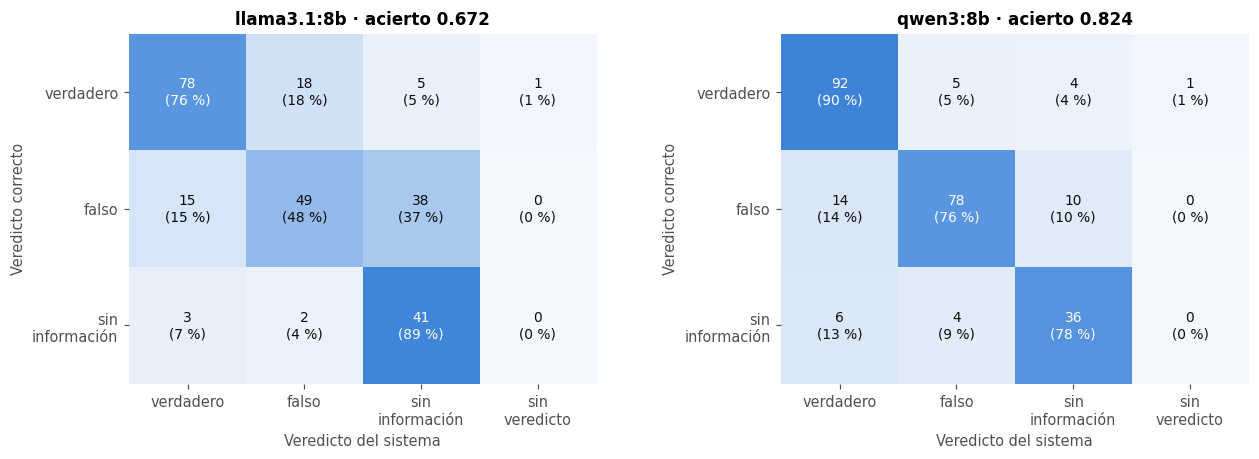

In [21]:
from matplotlib.colors import LinearSegmentedColormap
AZULES = LinearSegmentedColormap.from_list('azules', ['#f4f8fd', '#2a78d6'])
columnas = ETIQUETAS + ['(ninguno)']
nombres = ['verdadero', 'falso', 'sin\ninformación', 'sin\nveredicto']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, (modelo, e) in zip(axes, ev.items()):
    m = pd.crosstab(e['etiqueta'], e['veredicto'].fillna('(ninguno)')).reindex(index=ETIQUETAS, columns=columnas, fill_value=0)
    prop = m.div(m.sum(axis=1), axis=0)
    ax.imshow(prop.values, cmap=AZULES, vmin=0, vmax=1)
    for i in range(m.shape[0]):
        for j in range(m.shape[1]):
            ax.text(j, i, f'{m.iat[i, j]}\n({100 * prop.iat[i, j]:.0f} %)', ha='center', va='center', fontsize=9,
                    color='white' if prop.iat[i, j] > 0.55 else '#0b0b0b')
    ax.set_xticks(range(len(columnas)), nombres)
    ax.set_yticks(range(len(ETIQUETAS)), nombres[:3])
    ax.set(xlabel='Veredicto del sistema', ylabel='Veredicto correcto',
           title=f"{modelo} · acierto {e['acierta'].mean():.3f}")
    ax.grid(False)
    for lado in ax.spines.values():
        lado.set_visible(False)
plt.tight_layout()
plt.show()

- **`qwen3:8b` es claramente mejor**: acierta el 82 % de las afirmaciones frente al 67 % de `llama3.1:8b` (+0,152 [0,096; 0,208]), con F1 macro de 0,812 frente a 0,664. También cita más a menudo el documento del que sale la afirmación (71 % frente a 56 %).
- **`llama3.1:8b` tiende a decir *falso***: en las falsas solo acierta la mitad (48 %), y un 37 % las deja en *sin información*; en las verdaderas dice *falso* un 18 % de las veces. Su rechazo correcto, más alto que el de qwen (89 % frente a 78 %), es engañoso: viene casi todo de la regla del código (ver más abajo) y lo paga en las falsas.
- **El error principal de qwen es dar por verdaderas 14 falsas**, que se analizan más abajo. En las sin información rechaza el 78 %; en 10 de 46 responde *verdadero* o *falso* sin tener pruebas suficientes.
- **Prueba literal**: en una de cada cuatro respuestas, la frase "copiada" no aparece tal cual en los fragmentos. En las que hemos mirado, casi siempre junta frases de varios fragmentos o las recorta con "…", más que inventarlas, pero no se ha comprobado una a una.
- **Idioma**: según `langdetect`, todas las explicaciones que ve el usuario están en el idioma de la afirmación, con los dos modelos.
- **Tiempo**: qwen tarda 11,4 s de media (18 s en el percentil 90) frente a 2,5 s de llama; la búsqueda, 0,1 s. Es el precio de acertar más: aceptable para verificar afirmaciones de una en una, pero lento.

**¿Cuánto influye la regla del código?** En la sección 2.3 se añadió una regla: si el LLM dice *verdadero* o *falso* pero no copia ninguna frase de prueba, el veredicto pasa a *sin información*. Aquí se cuenta cuántas veces actúa, si acierta al hacerlo y cuál sería el acierto sin ella.

In [22]:
for modelo, e in ev.items():
    cambia = e['veredicto_llm'].notna() & (e['veredicto_llm'] != e['veredicto'])
    acierto_sin_regla = (e['veredicto_llm'] == e['etiqueta']).mean()
    print(f"{modelo}: la regla actúa en {cambia.sum()} respuestas; acierto con la regla {e['acierta'].mean():.3f}, sin ella {acierto_sin_regla:.3f}")
    if cambia.any():
        print(pd.crosstab(e.loc[cambia, 'etiqueta'], e.loc[cambia, 'veredicto_llm'].map(lambda v: f'el LLM dijo {v}'),
                          rownames=['veredicto correcto'], colnames=['']).to_string(), '\n')

llama3.1:8b: la regla actúa en 71 respuestas; acierto con la regla 0.672, sin ella 0.696
                    el LLM dijo falso
veredicto correcto                   
falso                              37
sin_informacion                    31
verdadero                           3 

qwen3:8b: la regla actúa en 2 respuestas; acierto con la regla 0.824, sin ella 0.832
                    el LLM dijo falso
veredicto correcto                   
falso                               2 



- **Con `llama3.1:8b`, la regla actúa en 71 respuestas (28 %)**: el LLM dice *falso* sin copiar ninguna frase de prueba. Acierta al cambiarlo en 31 (eran sin información), pero estropea 37 falsas que llama había acertado: sin la regla, su acierto sería 0,696 en vez de 0,672. llama no sigue bien la instrucción de copiar primero la prueba.
- **Con `qwen3:8b` actúa solo 2 veces**: cuando no encuentra prueba, ya responde *sin información* por sí mismo. El cambio del prompt de la sección 2.3 (pedir la prueba antes del veredicto) funciona con qwen, y la regla queda como red de seguridad.
- **Se mantiene la regla**: con qwen apenas cambia el resultado (2 respuestas), y garantiza que el sistema no da un veredicto que no puede apoyar en una frase de las fuentes.

**Cobertura e idioma.** El LLM solo puede acertar una afirmación verdadera o falsa si la búsqueda le trae el fragmento que la prueba. Se separan las 204 verdaderas y falsas según si el documento de origen está entre las 5 pruebas, y se compara inglés con español en las 50 afirmaciones traducidas, cada una frente a su original.

In [23]:
for modelo, e in ev.items():
    con_doc = e[e['etiqueta'] != 'sin_informacion']
    print(f'{modelo} - acierto en las verdaderas y falsas, según si se recupera el documento de origen:')
    print(con_doc.groupby(con_doc['recupera_doc'].map({True: 'recuperado', False: 'no recuperado'}))
          .agg(afirmaciones=('acierta', 'size'), acierto=('acierta', 'mean')).round(3).to_string(), '\n')

# Inglés frente a español: cada afirmación traducida con su original (mismo veredicto correcto)
print('Afirmaciones traducidas (50) y sus originales en inglés:')
filas = []
for modelo, e in ev.items():
    x = e.set_index('aid')
    es = [aid for aid in x.index if aid.endswith('_es')]
    en = [aid[:-3] for aid in es]
    con_doc = [aid for aid in es if x.at[aid, 'etiqueta'] != 'sin_informacion']
    filas.append({'modelo': modelo,
                  'acierto en': x.loc[en, 'acierta'].mean(), 'acierto es': x.loc[es, 'acierta'].mean(),
                  'es − en': texto_ic(*intervalo(x.loc[es, 'acierta'].values.astype(float) - x.loc[en, 'acierta'].values.astype(float))),
                  'Recall@5 en': x.loc[[a[:-3] for a in con_doc], 'recupera_doc'].mean(),
                  'Recall@5 es': x.loc[con_doc, 'recupera_doc'].mean()})
print(pd.DataFrame(filas).set_index('modelo').round(3).to_string())

llama3.1:8b - acierto en las verdaderas y falsas, según si se recupera el documento de origen:
               afirmaciones  acierto
recupera_doc                        
no recuperado            36    0.389
recuperado              168    0.673 

qwen3:8b - acierto en las verdaderas y falsas, según si se recupera el documento de origen:
               afirmaciones  acierto
recupera_doc                        
no recuperado            36    0.472
recuperado              168    0.911 

Afirmaciones traducidas (50) y sus originales en inglés:
             acierto en  acierto es                  es − en  Recall@5 en  Recall@5 es
modelo                                                                                
llama3.1:8b        0.78        0.64   -0.140 [-0.260, 0.000]         0.85         0.65
qwen3:8b           0.86        0.70  -0.160 [-0.300, -0.020]         0.85         0.65


- **La búsqueda es el límite principal.** En 36 de las 204 verdaderas y falsas (18 %), el documento de origen no está entre las 5 pruebas. Cuando está, qwen acierta el 91 %; cuando no, el 47 %. De los 19 fallos de ese grupo, 14 los responde como *sin información*, que es lo coherente con esas pruebas.
- **En español, el sistema es peor, y es por la búsqueda.** Con las mismas afirmaciones traducidas, el Recall@5 baja de 0,85 a 0,65, y el acierto de qwen, de 0,86 a 0,70 (−0,16 [−0,30; −0,02], una diferencia clara). BM25 apenas encuentra palabras en común entre una afirmación en español y un corpus en inglés, salvo los nombres propios, y e5 por sí solo recupera peor que la búsqueda híbrida (sección 1.6).

**Los errores, uno a uno.** Para entender qué falla, todas las afirmaciones en las que se equivoca `qwen3:8b`, agrupadas por tipo de error, con el principio de su explicación. *rec.* indica si el documento de origen estaba entre las pruebas.

In [24]:
e = ev['qwen3:8b']
errores = e[~e['acierta']].copy()
errores['tipo'] = errores['etiqueta'] + ' → ' + errores['veredicto'].fillna('sin veredicto')
for tipo, grupo in errores.groupby('tipo', sort=False):
    print(f'\n{tipo} ({len(grupo)})')
    for _, x in grupo.iterrows():
        rec = '' if x['etiqueta'] == 'sin_informacion' else (' rec.' if x['recupera_doc'] else ' no rec.')
        print(f"  {x['aid']:8s}{rec:9s} {x['afirmacion'][:95]}")
        if x['explicacion']:
            print(f"  {'':17s} → {x['explicacion'][:95]}")


falso → verdadero (14)
  a002     rec.     Opus I, king of the Epeians, was the son of Poseidon by Protogeneia, daughter of Deucalion.
                    → The evidence directly states that Opus I was the son of Zeus and Protogeneia, daughter of Deuca
  a006     rec.     Tarphe was a town of the Ozolian Locrians on the Boagrius River.
                    → The passage explicitly states that Tarphe was one of the towns of the Locrians located about th
  a008_es  rec.     Álope, hija de Áctor, dio a luz a Hipotoonte después de ser seducida por Poseidón, que había to
                    → La evidencia indica que Alope, hija de Cercyon, dio a luz a Hipotoonte después de ser seducida 
  a014     rec.     The Gosforth Cross, located in County Durham, features depictions of figures from Norse mytholo
                    → The Gosforth Cross is explicitly mentioned as depicting Norse mythological episodes connected t
  a022     rec.     Hjordis' son Helgi foresaw his death and spoke to Hethi

Los errores de qwen, por tipos:

- **Falsas que da por verdaderas (14).** En 12 tenía el fragmento correcto. Comprueba lo principal de la afirmación y pasa por alto el dato cambiado cuando es secundario: los locrios *ozolios* en vez de epicnemidios, *cinco* príncipes en vez de seis, la cueva del Sueño junto a los *Campos Elíseos* en vez de junto a los cimerios, Dido fundando *Tiro* en vez de Cartago. En a002 la propia explicación dice "hijo de Zeus" y aun así responde *verdadero*.
- **Verdaderas o falsas que deja sin información (14).** En ninguna estaba el documento de origen entre las pruebas, y 9 son en español. El LLM hace lo correcto con lo que tiene; el fallo es de la búsqueda.
- **Verdaderas que da por falsas (5).** Varias son problemas del propio conjunto más que del sistema. La muerte de Androgeo tiene **varias versiones en el corpus** (en Atenas, de camino a Tebas, en una batalla): es justo el caso *depende de la fuente* que queda para el Hito 3. *Lycophron* es un nombre que comparten varios personajes, y *Palante* es la forma española de *Pallas*, que el LLM no reconoce como el mismo nombre.
- **Sin información que da por verdaderas (6).** Isis, las vilas y Rávana sí aparecen de pasada en el corpus (Apuleyo, el artículo sobre los elfos, una mención de Lanka), y el LLM da por buena toda la afirmación con una prueba que solo cubre una parte. Es un fallo del sistema, pero también indica que estas afirmaciones no son del todo "sin información".
- **Sin información que da por falsas (4).** Tres son detalles inventados (la lira de Eneas, el brazalete de Tyr, la danza de Apolo) que el LLM "desmiente" con otro dato parecido de los fragmentos (la rama dorada que la Sibila le pide a Eneas). Es discutible: los fragmentos no hablan de esa lira, pero tampoco son del todo ajenos. En la cuarta (Garuda, de la mitología hindú) dice que los fragmentos la contradicen; no lo hemos comprobado.
- **Sin veredicto (1)**: una respuesta sin veredicto válido.

**Decisión: el sistema usa `qwen3:8b`.** Acierta bastante más y sigue mejor la instrucción de apoyarse en una prueba, a cambio de tardar unos 11 s por afirmación. Para el siguiente hito, los puntos débiles son claros: la búsqueda con afirmaciones en español, que el LLM compruebe todos los datos de la afirmación y no solo el principal, y las afirmaciones cuyas fuentes no coinciden (*depende de la fuente*).